🔸 Initial Q-table (should be empty):

✅ Final Q-table sample (first 10 entries):
(('W', 'W', 'W', 'W', 'E', 'E', 'W', 'E', 'O'), 0): [-19. -10. -19. -10.]
(('W', 'E', 'E', 'W', 'E', 'O', 'W', 'E', 'O'), 0): [-10. -10. -19. -19.]
(('W', 'W', 'W', 'E', 'E', 'E', 'E', 'O', 'O'), 0): [-19. -19. -10. -10.]
(('W', 'E', 'O', 'W', 'E', 'O', 'W', 'E', 'E'), 0): [-10. -10. -19. -19.]
(('W', 'W', 'W', 'E', 'E', 'E', 'O', 'O', 'O'), 0): [-19. -19. -10. -10.]
(('W', 'W', 'W', 'E', 'E', 'E', 'O', 'O', 'E'), 0): [-19. -19. -10. -10.]
(('W', 'W', 'W', 'E', 'E', 'E', 'O', 'E', 'E'), 0): [-19. -10. -10. -10.]
(('E', 'E', 'E', 'O', 'E', 'E', 'O', 'E', 'E'), 0): [-10. -10. -19. -10.]
(('W', 'W', 'W', 'E', 'E', 'E', 'E', 'E', 'E'), 0): [-19. -10. -10. -10.]
(('E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E'), 0): [-10. -10. -10. -10.]
(('O', 'E', 'E', 'O', 'E', 'E', 'O', 'E', 'E'), 0): [-10. -10. -19. -10.]


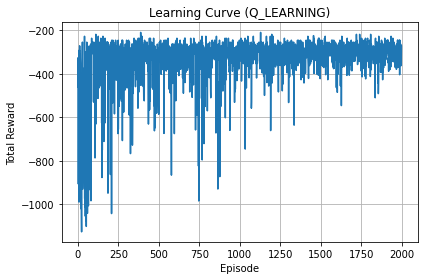

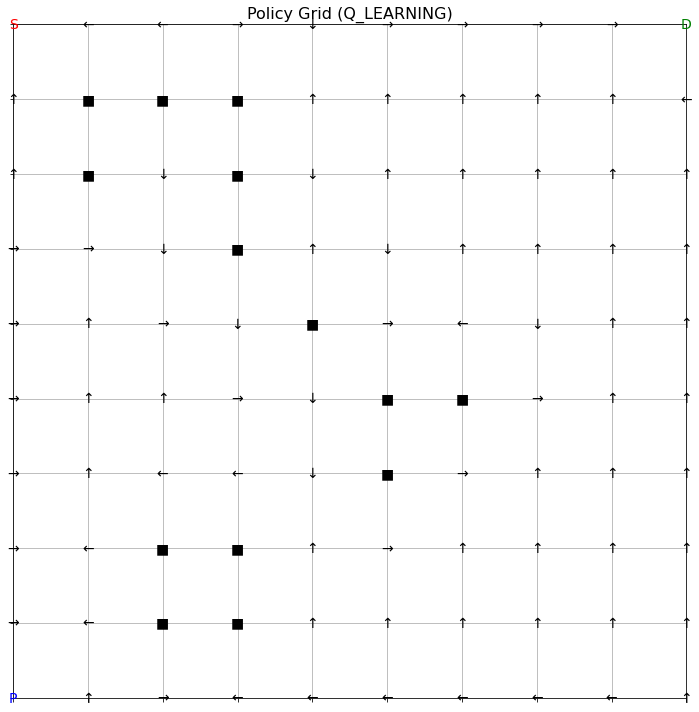

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

# ========================================
# 🤖 PROBLEM SETTING & PARTIAL OBSERVABILITY
# ========================================
# This warehouse environment is **partially observable**:
#   - The robot cannot observe its absolute (x, y) position.
#   - It only sees a 3x3 grid around its current location (local view).
#
# Normally, Q-learning assumes full observability (i.e., Q(s, a) for known states).
# But here, we adapt Q-learning to work in partial observability by:
#   - Defining state as (local_view, carrying), where local_view is a tuple of 9 values.
#   - The robot learns a Q-value for each observed 3x3 configuration + carrying state.
#
# 🔍 Justification:
#   - Q-learning can still converge in partially observable environments if:
#       - There are repeated observable configurations.
#       - The robot's actions can meaningfully affect long-term rewards.
#   - This models real-world robots or drones that only see part of the world at each step.
#   - SARSA is also available here for on-policy (safer) learning under the same state representation.

# ========================================
# 🧠 Algorithm Selection:
# ========================================
algorithm = 'q_learning'  # or 'sarsa'

# ========================================
# 🧱 Environment Setup
# ========================================
GRID_SIZE = 10
OBSTACLES = {
    (1, 1), (1, 2), (1, 3), (2, 1), (2, 3), (3, 3), (4, 4),
    (5, 5), (5, 6), (6, 5), (7, 2), (8, 2), (7, 3), (8, 3)
}
PICKUP_LOCATION = (9, 0)
DROPOFF_LOCATION = (0, 9)
START_LOCATION = (0, 0)

ACTIONS = ['UP', 'DOWN', 'LEFT', 'RIGHT']
ACTION_MAP = {'UP': (-1, 0), 'DOWN': (1, 0), 'LEFT': (0, -1), 'RIGHT': (0, 1)}
ARROWS = {'UP': '↑', 'DOWN': '↓', 'LEFT': '←', 'RIGHT': '→'}

# ========================================
# ⚙️ Learning Parameters
# ========================================
alpha = 0.1      # Learning rate: how quickly to update Q-values
gamma = 0.9      # Discount factor: how much to value future rewards
epsilon = 0.2    # Exploration rate: chance to explore random actions
episodes = 2000  # Total number of training episodes

# ========================================
# 🧱 Helper Functions
# ========================================
def is_valid(pos):
    x, y = pos
    return 0 <= x < GRID_SIZE and 0 <= y < GRID_SIZE and (x, y) not in OBSTACLES

def get_local_view(x, y):
    """Return 3x3 view centered at (x, y) as a tuple of 9 characters."""
    view = []
    for dx in [-1, 0, 1]:
        for dy in [-1, 0, 1]:
            nx, ny = x + dx, y + dy
            if 0 <= nx < GRID_SIZE and 0 <= ny < GRID_SIZE:
                if (nx, ny) in OBSTACLES:
                    view.append('O')
                elif (nx, ny) == PICKUP_LOCATION:
                    view.append('P')
                elif (nx, ny) == DROPOFF_LOCATION:
                    view.append('D')
                else:
                    view.append('E')
            else:
                view.append('W')  # Wall or out-of-bounds
    return tuple(view)

Q_table = {}

def get_Q(local_view, carrying):
    """Return Q-values for a given state or initialize if unseen."""
    key = (local_view, carrying)
    if key not in Q_table:
        Q_table[key] = np.zeros(len(ACTIONS))
    return Q_table[key]

def take_action(x, y, carrying, action):
    """Simulate moving in the grid and returning next state and reward."""
    dx, dy = ACTION_MAP[action]
    new_x, new_y = x + dx, y + dy
    if not is_valid((new_x, new_y)):
        return x, y, -10, carrying  # Invalid move penalty
    reward = -1
    if not carrying and (new_x, new_y) == PICKUP_LOCATION:
        carrying = 1
        reward = 10
    elif carrying and (new_x, new_y) == DROPOFF_LOCATION:
        carrying = 0
        reward = 20
    elif carrying and (new_x, new_y) != DROPOFF_LOCATION:
        reward = -5
    return new_x, new_y, reward, carrying

# ========================================
# 🔁 Training Loop
# ========================================
print("🔸 Initial Q-table (should be empty):")
for i, key in enumerate(Q_table.keys()):
    print(f"{key}: {Q_table[key]}")
    if i >= 10:
        break

rewards_per_episode = []

for episode in range(episodes):
    x, y = START_LOCATION
    carrying = 0
    total_reward = 0

    local_view = get_local_view(x, y)
    Q_values = get_Q(local_view, carrying)
    action_idx = random.randint(0, 3) if random.uniform(0, 1) < epsilon else np.argmax(Q_values)
    action = ACTIONS[action_idx]

    for _ in range(200):
        new_x, new_y, reward, new_carrying = take_action(x, y, carrying, action)
        next_local_view = get_local_view(new_x, new_y)
        next_Q = get_Q(next_local_view, new_carrying)

        if algorithm == 'q_learning':
            # Q-learning: off-policy
            Q_values[action_idx] += alpha * (reward + gamma * np.max(next_Q) - Q_values[action_idx])
            next_action_idx = random.randint(0, 3) if random.uniform(0, 1) < epsilon else np.argmax(next_Q)
        elif algorithm == 'sarsa':
            # SARSA: on-policy
            next_action_idx = random.randint(0, 3) if random.uniform(0, 1) < epsilon else np.argmax(next_Q)
            Q_values[action_idx] += alpha * (reward + gamma * next_Q[next_action_idx] - Q_values[action_idx])

        x, y, carrying = new_x, new_y, new_carrying
        local_view = next_local_view
        Q_values = next_Q
        action_idx = next_action_idx
        action = ACTIONS[action_idx]
        total_reward += reward

    rewards_per_episode.append(total_reward)

# ========================================
# 🧾 Final Q-table (sample)
# ========================================
print("\n✅ Final Q-table sample (first 10 entries):")
for i, (key, value) in enumerate(Q_table.items()):
    print(f"{key}: {value}")
    if i >= 10:
        break

# ========================================
# 📈 Learning Curve
# ========================================
plt.plot(rewards_per_episode)
plt.title(f"Learning Curve ({algorithm.upper()})")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.tight_layout()
plt.show()

# ========================================
# 🗺️ Policy Grid Visualization
# ========================================
policy_grid = np.full((GRID_SIZE, GRID_SIZE), '', dtype=object)

for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
        pos = (i, j)
        if pos in OBSTACLES:
            policy_grid[i, j] = '■'
        elif pos == PICKUP_LOCATION:
            policy_grid[i, j] = 'P'
        elif pos == DROPOFF_LOCATION:
            policy_grid[i, j] = 'D'
        elif pos == START_LOCATION:
            policy_grid[i, j] = 'S'
        else:
            view = get_local_view(i, j)
            Q_vals = get_Q(view, 0)
            best_action = ACTIONS[np.argmax(Q_vals)]
            policy_grid[i, j] = ARROWS[best_action]

# Plot grid with color-coded cells and directions
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_title(f"Policy Grid ({algorithm.upper()})", fontsize=16)
ax.set_xticks(np.arange(GRID_SIZE))
ax.set_yticks(np.arange(GRID_SIZE))
ax.set_xticklabels([])
ax.set_yticklabels([])
for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
        text = policy_grid[i, j]
        color = (
            'red' if (i, j) == START_LOCATION else
            'blue' if (i, j) == PICKUP_LOCATION else
            'green' if (i, j) == DROPOFF_LOCATION else
            'black'
        )
        ax.text(j, i, text, va='center', ha='center', fontsize=14, color=color)
ax.invert_yaxis()
ax.set_aspect('equal')
plt.grid(True)
plt.tight_layout()
plt.show()
